# 🌸 Iris Flower Classification: Decision Tree vs. K-Nearest Neighbors

## 1. The Idea

**What does the model predict?**
Given four measurements of an iris flower (sepal length, sepal width, petal length, petal width, all in cm), the model predicts which of three species it is: **setosa**, **versicolor** or **virginica**.

**Why is it useful?**
- Identifying species from measurements is a classic, real task in botany and ecology, where field workers can measure a flower faster than they can consult an expert.
- The same recipe (measure features → train a classifier → check accuracy) applies to many real problems, such as diagnosing from lab results or sorting products by specs.
- Iris is small, clean and well understood, so it is ideal for learning the full machine learning workflow and comparing two simple models fairly.

**Dataset:** the Iris dataset (R. A. Fisher, 1936), 150 flowers, 50 per species. Source: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris). It also ships inside scikit-learn, which is how this notebook loads it (no download needed).

## 2. Data Preparation
Load the data, inspect it, check for missing values, then separate the **features** (inputs) from the **target** (what we predict).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Load the dataset as a pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [2]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (150, 6)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [3]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Total missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Total missing values: 0
Duplicate rows: 1


In [4]:
# Summary statistics and class balance
print(df.describe().round(2))
print()
print("Flowers per species:")
print(df["species"].value_counts())

       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target
count             150.00            150.00             150.00            150.00  150.00
mean                5.84              3.06               3.76              1.20    1.00
std                 0.83              0.44               1.77              0.76    0.82
min                 4.30              2.00               1.00              0.10    0.00
25%                 5.10              2.80               1.60              0.30    0.00
50%                 5.80              3.00               4.35              1.30    1.00
75%                 6.40              3.30               5.10              1.80    2.00
max                 7.90              4.40               6.90              2.50    2.00

Flowers per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


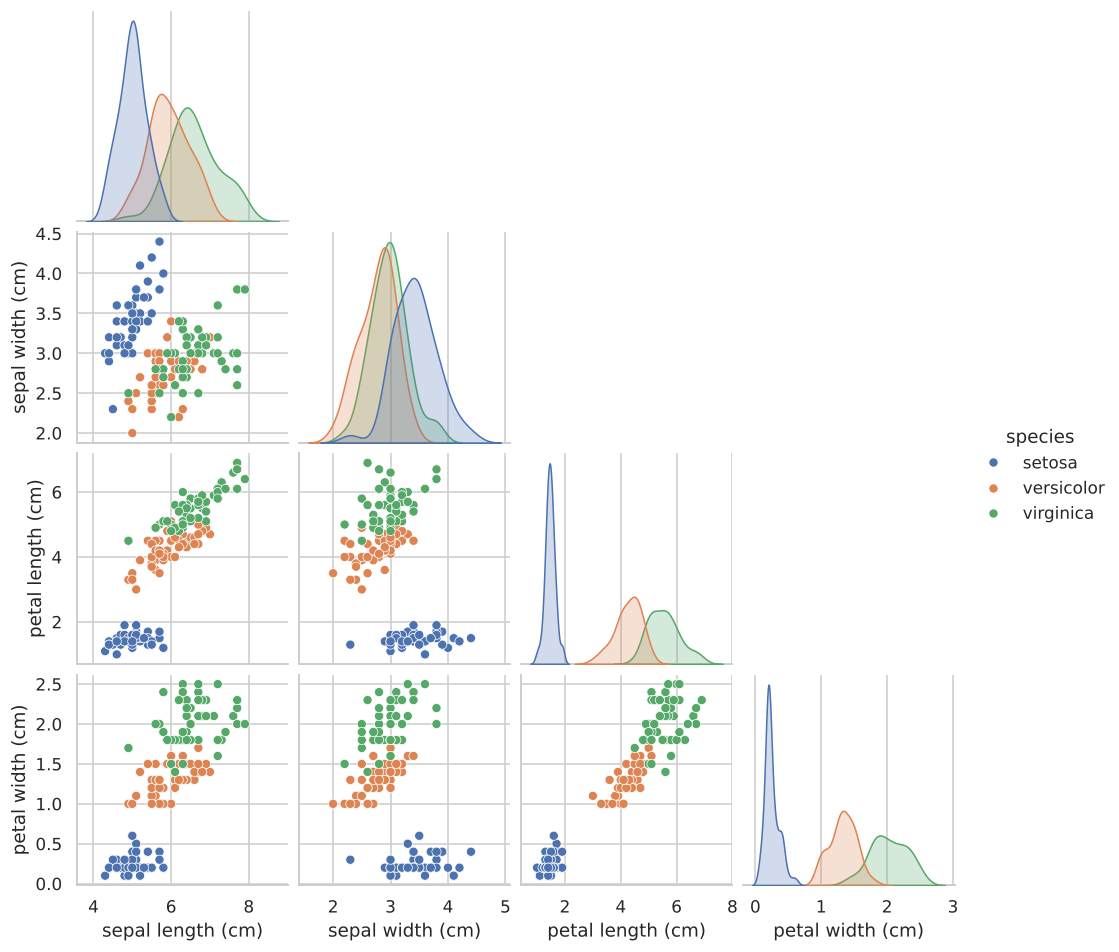

In [5]:
# Quick look at how the species differ
sns.pairplot(df.drop(columns="target"), hue="species", corner=True, height=2.2)
plt.show()

**What the data shows:** there are no missing values (and just one duplicated row, which is a known quirk of this dataset and harmless, so we keep it). The three species are perfectly balanced (50 each). In the plots, *setosa* is clearly separated from the others, especially by petal size, while *versicolor* and *virginica* overlap a little. We should expect that overlap to be where any mistakes happen.

Now we define the features and target and split the data. We hold out 20% for testing, and `stratify=y` keeps the species balanced in both parts.

In [6]:
feature_names = iris.feature_names
X = df[feature_names]   # features: 4 measurements
y = df["target"]        # target: species as 0, 1, 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Class names:", [str(n) for n in iris.target_names])

Training set: (120, 4) | Test set: (30, 4)
Class names: ['setosa', 'versicolor', 'virginica']


## 3. Model Building
Two beginner-friendly models:

1. **Decision Tree**: learns a series of yes/no questions about the measurements (for example "petal length < 2.5?"). It does not need scaled features. We cap `max_depth=3` so it stays simple and does not memorize the training data.
2. **K-Nearest Neighbors (KNN)**: classifies a flower by looking at its `k = 5` most similar training flowers and taking a majority vote. KNN relies on distances, so we standardize the features first (inside a pipeline so the scaler only learns from training data).

In [7]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

tree.fit(X_train, y_train)
knn.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


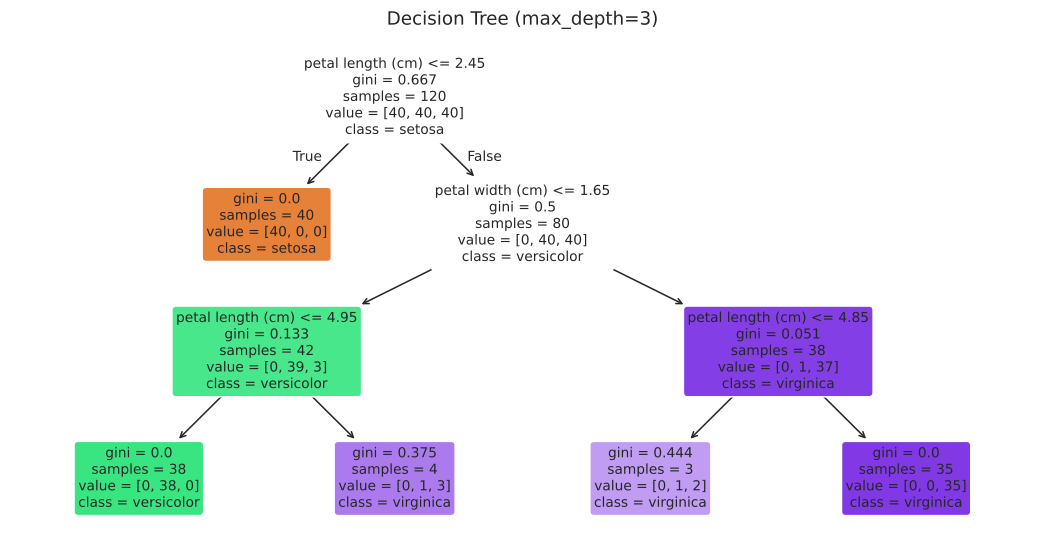

In [8]:
# The learned decision tree: easy to read and explain
plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=feature_names, class_names=list(iris.target_names),
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3)")
plt.show()

## 4. Evaluation
We compare the two models on the **unseen test set** using accuracy, and show a confusion matrix for each. In a confusion matrix, rows are the true species and columns are the predicted species, so anything off the diagonal is a mistake.

Decision Tree    0.967
KNN (k=5)        0.933


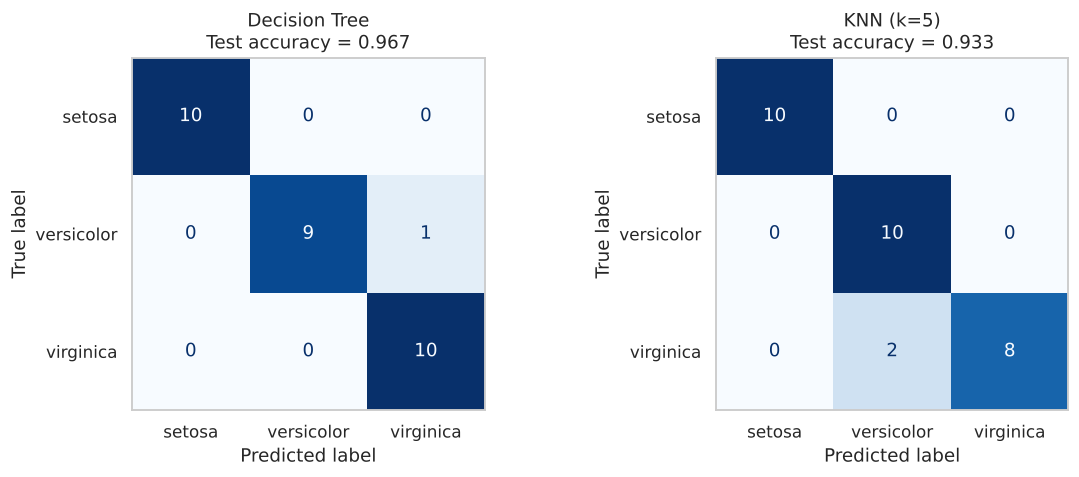

In [9]:
models = {"Decision Tree": tree, "KNN (k=5)": knn}
results = {}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nTest accuracy = {acc:.3f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

print(pd.Series(results, name="Test accuracy").round(3).to_string())

With only 30 test flowers, one extra mistake changes accuracy by about 3 percentage points, so a single split can be misleading. As a sturdier check, we also use **5-fold cross-validation** on the full dataset, which tests each model on five different splits.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name,
                    "Test-set accuracy": round(results[name], 3),
                    "CV mean accuracy": round(scores.mean(), 3),
                    "CV std": round(scores.std(), 3),
                    "Fold scores": np.round(scores, 3).tolist()})

comparison = pd.DataFrame(cv_rows).set_index("Model")
print(comparison.to_string())

               Test-set accuracy  CV mean accuracy  CV std                        Fold scores
Model                                                                                        
Decision Tree              0.967             0.960   0.025  [0.967, 0.967, 0.933, 1.0, 0.933]
KNN (k=5)                  0.933             0.973   0.025    [1.0, 0.967, 0.933, 1.0, 0.967]


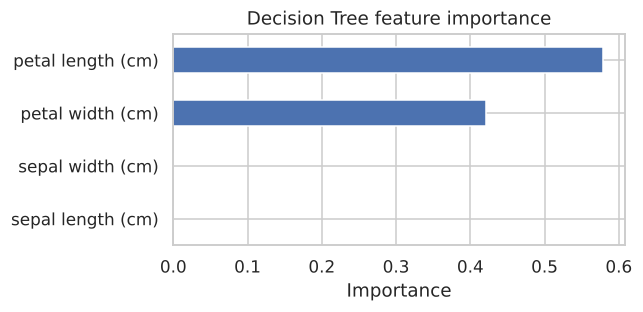

In [11]:
# Bonus: which petal/sepal measurements does the tree rely on most?
importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
importances.plot(kind="barh", figsize=(6, 3), color="#4C72B0")
plt.title("Decision Tree feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 5. Conclusion

**Which model performed better?** It depends on how you measure, and that is the most useful finding here.

| Model | Test-set accuracy (30 flowers) | 5-fold CV accuracy (150 flowers) |
|---|---|---|
| Decision Tree (max_depth=3) | **96.7%** (29/30) | 96.0% ± 2.5% |
| KNN (k=5, scaled) | 93.3% (28/30) | **97.3%** ± 2.5% |

- On the single held-out test set, the **Decision Tree won** by one flower. Its only error was a *versicolor* predicted as *virginica*; KNN mistook two *virginica* for *versicolor*.
- Under cross-validation, which averages over five different splits, **KNN edged ahead** by 1.3 points, about two flowers out of 150.
- That gap is smaller than the fold-to-fold variation (±2.5 points), so the honest verdict is that **the two models are essentially tied** on this dataset. If I had to choose one on evidence, I would lean slightly toward KNN because its score comes from more data, but I would not claim it is truly better.

**What I learned**
1. **One train/test split can mislead.** With only 30 test flowers, a single mistake moves accuracy by 3.3 points and can even flip the ranking. Cross-validation gives a more trustworthy comparison.
2. **Both models make their mistakes in the same place:** *versicolor* vs. *virginica*. *Setosa* was classified perfectly every time, matching what the pair plot suggested.
3. **The decision tree is easy to explain.** It reached ~97% using just two questions about petal length and petal width (the sepal measurements had zero importance), so petals carry nearly all the signal. KNN cannot give that kind of explanation.
4. **Preprocessing depends on the model.** KNN needs scaled features because it uses distances; the tree does not. Putting the scaler inside a pipeline keeps test data from leaking into training.

**Limitations and next steps:** Iris is small and very clean, so these scores are optimistic compared with messy real-world data. Natural next steps are tuning `k` and `max_depth` with a grid search, trying a Random Forest, or repeating this on a harder dataset such as mushroom classification.